In [ ]:
# # CS 763 - Lab 8 (WGAN-GPs) Part-B

from torch.autograd import grad
from tqdm import tqdm
import time
import sys
import os
import PIL
from torch.nn import functional as F
from torch import nn, optim
from torchvision import transforms, models, datasets
import matplotlib.pyplot as plt
import torchvision
import random
import torch
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/Sem 6 Docs/CV Labs/180050085_180050090_180070060_lab08
%ls

/content/drive/MyDrive/Sem 6 Docs/CV Labs/180050085_180050090_180070060_lab08
code/  convincingDirectory/  data/  images/  readme.gdoc  readme.txt  results/


In [ ]:
# Check for GPU specs
get_ipython().system('nvidia-smi')


# device set to cuda if GPU available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Function to fix the seed for randomisation


def fix_seed(seed=0):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # if you are using multi-GPU.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


fix_seed(763)

Mon Apr 19 10:31:18 2021       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 460.67       Driver Version: 460.32.03    CUDA Version: 11.2     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  Tesla T4            Off  | 00000000:00:04.0 Off |                    0 |
| N/A   54C    P8    10W /  70W |      0MiB / 15109MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
                                                                               
+-------

Lenth of Trainset = 60000
Lenth of Testset = 10000
Dimensions of each image = (28,28)


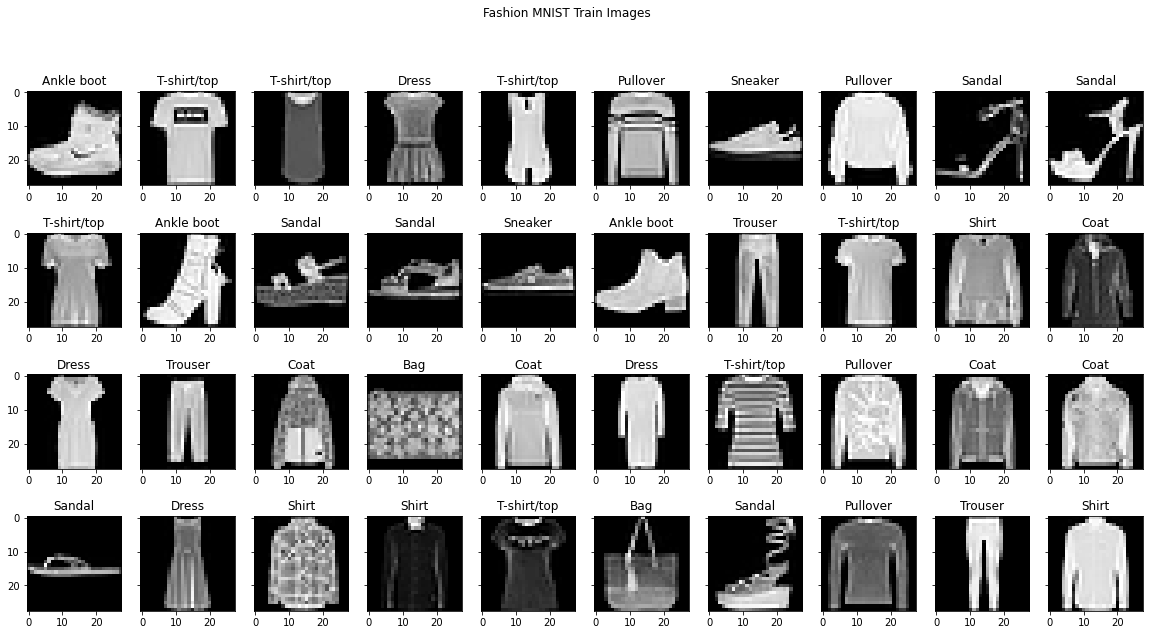

In [ ]:
# We will use the Fashion-MNIST dataset for this task
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5), std=(0.5))])

trainset = torchvision.datasets.FashionMNIST(
    './data', download=True, train=True, transform=transform)
testset = torchvision.datasets.FashionMNIST(
    './data', download=True, train=False, transform=transform)

# dataloaders
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=128, num_workers=2, shuffle=True)
testloader = torch.utils.data.DataLoader(
    trainset, batch_size=128, num_workers=2)


# Visualising the dataset
labeldic = {}
labeldic[0] = 'T-shirt/top'
labeldic[1] = 'Trouser'
labeldic[2] = 'Pullover'
labeldic[3] = 'Dress'
labeldic[4] = 'Coat'
labeldic[5] = 'Sandal'
labeldic[6] = 'Shirt'
labeldic[7] = 'Sneaker'
labeldic[8] = 'Bag'
labeldic[9] = 'Ankle boot'
print('Lenth of Trainset = {}'.format(len(trainset)))
print('Lenth of Testset = {}'.format(len(testset)))
print('Dimensions of each image = ({},{})'.format(
    trainset[0][0].shape[1], trainset[0][0].shape[2]))
fig, axs = plt.subplots(4, 10, sharey=True, figsize=(20, 10))
for i in range(40):
    axs[i//10, i % 10].imshow(trainset[i][0].squeeze(), cmap='gray')
    axs[i//10, i % 10].set_title('{}'.format(labeldic[trainset[i][1]]))
plt.suptitle('Fashion MNIST Train Images')
plt.show()

In [ ]:
# Generator and Discriminator Architecures
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        ## TODO ##
        self.in_channels = 110
        self.out_channels = 1

        self.model = nn.Sequential(
            # (110, 1, 1)
            nn.ConvTranspose2d(self.in_channels, 128, kernel_size=4, stride=1, padding=0),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # (128, 4, 4)
            nn.ConvTranspose2d(128, 64, kernel_size=10, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            # (64, 14, 14)
            nn.ConvTranspose2d(64, self.out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
            # (1, 28, 28)
        )
        ## TODO ##

    # forward pass
    def forward(self, x, labels):
        ## TODO ##
        # x = (_, 100, 1, 1)
        # labels = (_, 1)
        y = F.one_hot(labels, 10).view(x.shape[0], 10, 1, 1).to(device)
        x = torch.cat([x, y], dim = 1)
        return self.model(x)
        ## TODO ##


class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        ## TODO ##
        self.in_channels = 11
        self.model = nn.Sequential(
            # (11, 28, 28)
            nn.Conv2d(self.in_channels, 64, kernel_size=4, stride=2, padding=1),
            # nn.InstanceNorm2d(256, affine=True),
            nn.LeakyReLU(0.2, inplace=True),
            # (64, 14, 14)
            nn.Conv2d(64, 128, kernel_size=10, stride=2, padding=1),
            # nn.InstanceNorm2d(1024, affine=True),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # (128, 4, 4)
            nn.Conv2d(128, 1, kernel_size=4, stride=1, padding=0),
            # (1, 1, 1)
            nn.Flatten(),
            nn.Linear(1, 1),
            nn.Sigmoid()
        )
        ## TODO ##

    # forward pass
    def forward(self, x, labels):
        ## TODO ##
        # x = (_, 1, 28, 28)
        # labels = (_, 1)
        y = F.one_hot(labels, 10).view(x.shape[0], 10, 1, 1).to(device)
        y = y.repeat(1, 1, x.shape[2], x.shape[3])
        x = torch.cat([x, y], dim = 1)
        return self.model(x)
        ## TODO ##


        # Create the models
G = Generator().to(device)
D = Discriminator().to(device)

Generator(
  (model): Sequential(
    (0): ConvTranspose2d(110, 128, kernel_size=(4, 4), stride=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(128, 64, kernel_size=(10, 10), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)
Discriminator(
  (model): Sequential(
    (0): Conv2d(11, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(10, 10), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 1, kernel_size=(4, 4), stride=(1, 1))
    (6): Flatten(start_

In [ ]:
# Define the Optimizer
## TODO ##
learning_rate = 1e-4
b1 = 0.5
b2 = 0.999
optimizer_g = optim.Adam(G.parameters(), lr = learning_rate, betas = (b1, b2))
optimizer_d = optim.Adam(D.parameters(), lr = learning_rate, betas = (b1, b2))
one = torch.tensor(1, dtype=torch.float)
mone = one * -1
## TODO ##

# Define the Washerstein Loss functions
lamda = 10

In [ ]:
def get_WLoss_generator(fake_images, labels):
    ## TODO ##
    score_fake = D(fake_images, labels).mean()
    # score_fake.backward(mone)
    return -score_fake
    ## TODO ##


def get_WLoss_discriminator(fake_images, true_images, labels):
    ## TODO ##
    score_real = D(true_images, labels).mean()
    # score_real.backward(mone)
    score_fake = D(fake_images, labels).mean()
    # score_fake.backward(one)
    grad_penalty = get_gradient_regularisation(fake_images, true_images, labels)
    # grad_penalty.backward()
    return score_fake - score_real + grad_penalty
    ## TODO ##


def get_gradient_regularisation(fake_images, true_images, labels):
    ## TODO ##
    gradients = get_grad(fake_images, true_images, labels)
    grad_penalty = ((gradients.norm(2, dim=1) - 1)**2).mean() * lamda
    return grad_penalty
    ## TODO ##


def get_grad(fake_images, true_images, labels):
    epsilon = torch.FloatTensor(np.random.uniform(
        size=(fake_images.shape[0], 1, 1, 1))).to(device)
    xbar = epsilon*true_images + (1-epsilon)*fake_images
    xbar.requires_grad_()
    lipschitz_grad = grad(
        outputs=D(xbar, labels).sum(),
        inputs=xbar,
        create_graph=True,
        retain_graph=True)[0]
    return lipschitz_grad.view(xbar.shape[0], -1)

# Train Function
# returns the total loss for the epoch


def train(epoch):
    loss_acc_g = 0
    loss_acc_d = 0

    for i, (images, labels) in tqdm(enumerate(trainloader), desc="Training for epoch {}".format(epoch), total=len(trainloader)):
        # Discriminator Training
        optimizer_d.zero_grad()
        ## TODO ##

        for p in D.parameters():
            p.requires_grad = True
        batch_size = images.shape[0]
        images = images.to(device)
        labels = labels.to(device)
        z = torch.randn(batch_size, 100, 1, 1).to(device)
        fake_images = G(z, labels)
        loss_d = get_WLoss_discriminator(fake_images, images, labels)
        loss_d.backward()

        ## TODO ##
        optimizer_d.step()

        if i % 5 == 0:
            # Generator training
            optimizer_g.zero_grad()
            ## TODO ##

            for p in D.parameters():
                p.requires_grad = False

            z = torch.randn(batch_size, 100, 1, 1).to(device)
            fake_images = G(z, labels)
            loss_g = get_WLoss_generator(fake_images, labels)
            loss_g.backward()

            for p in D.parameters():
                p.requires_grad = True

            ## TODO ##
            optimizer_g.step()
            loss_acc_g += loss_g.item()
        loss_acc_d += loss_d.item()

    return (loss_acc_g/(i/5)+loss_acc_d/i), loss_acc_g/(i/5), loss_acc_d/i


In [ ]:
# Functions to save and load checkpoints
# Enter the path on your shared drive where the checkpoint is to be saved
## TODO ##
path_to_checkpoint = './results/cwgan'
## TODO ##


def save_checkpoint(e):
    if not os.path.isdir(path_to_checkpoint):
        os.mkdir(path_to_checkpoint)
    torch.save({'e': e, 'gen': G.state_dict(), 'disc': D.state_dict(), 'optim_d': optimizer_d.state_dict(
    ), 'optim_g': optimizer_g.state_dict()}, os.path.join(path_to_checkpoint, 'checkpoint_cwgan.pth'))


def load_checkpoint():
    if not os.path.isfile(os.path.join(path_to_checkpoint, 'checkpoint_cwgan.pth')):
        return -1
    dic = torch.load(os.path.join(path_to_checkpoint, 'checkpoint_cwgan.pth'))
    G.load_state_dict(dic['gen'])
    D.load_state_dict(dic['disc'])
    optimizer_d.load_state_dict(dic['optim_d'])
    optimizer_g.load_state_dict(dic['optim_g'])
    return dic['e']

In [ ]:
# The generate functions are defined here
# Should return a nx28x28 numpy array


def generate(n, ci):
    ## TODO ##
    z = torch.randn((n, 100, 1, 1)).to(device)
    ci = torch.tensor(ci).view(1, 1).repeat(n, 1).to(device)
    images = G(z, ci).to("cpu").detach()
    return images
    ## TODO ##

## TODO ##
NUM_EPOCHS = 100
## TODO ##

losses_g = []
losses_d = []

# Resume training
offset = load_checkpoint()
if os.path.exists('images/cwgan'):
    if offset == -1:
        os.system('rm -rf images/cwgan')
        os.mkdir('images/cwgan')
else:
    os.mkdir('images/cwgan')



In [ ]:
for e in range(NUM_EPOCHS):
    if e <= offset:
        continue
    loss, loss_g, loss_d = train(e)
    losses_g.append(loss_g)
    losses_d.append(loss_d)
    G.eval()
    li = torch.randint(0, 10, (1,))[0].item()
    g_output = generate(1, li)[0]
    G.train()
    plt.imshow(g_output.reshape(28, 28), cmap='gray')
    plt.title('Category: {}'.format(labeldic[li]))
    plt.savefig('./images/cwgan/{}.png'.format(e))
    print('loss_g = {}, loss_d = {}\n'.format(loss_g, loss_d))
    save_checkpoint(e)


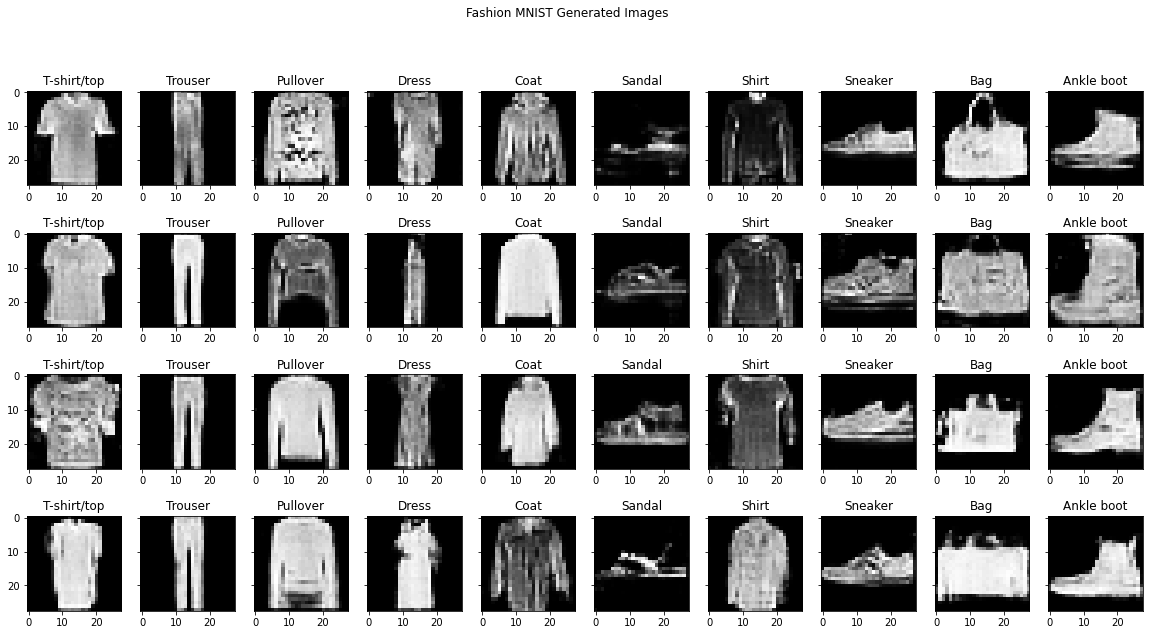

In [ ]:
# Test script
load_checkpoint()
with torch.no_grad():
    G.eval()
    fig, axs = plt.subplots(4, 10, sharey=True, figsize=(20, 10))
    for i in range(40):
        fake_image = generate(1, i % 10)[0]
        axs[i//10, i % 10].imshow(fake_image.reshape(28, 28), cmap='gray')
        axs[i//10, i % 10].set_title('{}'.format(labeldic[i % 10]))
    plt.suptitle('Fashion MNIST Generated Images')
    plt.show()